# Why a drone flies: lift, momentum and real air density

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/why_drones_fly_hluboka_en.ipynb)

**OpenSkyLab · notebook for the lab** [Why a drone flies](https://openskylab.space/edu_viz_why_drones_fly.html) · [česká verze](why_drones_fly_hluboka_cs.ipynb)

The lab explains airfoil lift, the stall angle, rotor momentum theory and dangerous descent regimes. Here you apply momentum theory to real drones (DJI Mavic 3 Enterprise and Matrice 350 RTK) and to real air density computed from weather in the mountains and in the lowlands.

**Goal:** compute the lift of a thin airfoil and its limit, induced velocity and hover power, show how air density changes endurance, and estimate the descent rate at which the vortex ring state threatens.

**Data:** hourly temperature, pressure and humidity for the last 92 days from Open-Meteo for České Budějovice, Plechý and Großglockner; mass, propeller diameter, battery and endurance of the drones from DJI data sheets.

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 45 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

> **💻 What the code does:** Optional cell. If you paste the settings copied from the lab and run it, the cells below take the same parameter values and say so for each one. If you leave it empty, the default values are used. It downloads nothing.

In [1]:
#@title Settings from the lab (optional)
#@markdown In the lab, click the Notebook link. The settings are copied; paste them here in place of `{}` (Ctrl+V) and run the cell.
Z_VIZUALU = {}  #@param {type:"raw"}
STEM = "why_drones_fly"

def z_viz(name, default, mapping=None):
    """Value of a parameter from the lab if the pasted code contains it; otherwise the default value."""
    z = Z_VIZUALU if isinstance(Z_VIZUALU, dict) and Z_VIZUALU.get("osl") == STEM else {}
    if name not in z:
        return default
    v = z[name]
    if mapping is not None:
        if v not in mapping:
            print(f"{name}: value {v!r} from the lab is not in this notebook, keeping {default!r}")
            return default
        v = mapping[v]
    elif isinstance(default, bool):
        v = bool(v)
    elif isinstance(default, int):
        v = int(round(v))
    elif isinstance(default, float):
        v = float(v)
    print(f"{name} = {v!r}  (from the lab)")
    return v

if isinstance(Z_VIZUALU, dict) and Z_VIZUALU and Z_VIZUALU.get("osl") != STEM:
    print(f"The pasted code is from another lab ({Z_VIZUALU.get('osl')}), the notebook does not use it.")

## 1. Setup

> **💻 What the code does:** Loads the libraries and defines the function `open_meteo`, which queries the Open-Meteo weather service. If the service does not answer or is overloaded, the function retries several times with a growing pause. It stores the parameters of two drones from DJI data sheets: mass, number of rotors, propeller diameter, battery energy and hover time. Nothing is downloaded yet.

In [2]:
import time, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def open_meteo(params, tries=6):
    """Query Open-Meteo; retry on errors or when the daily limit is exceeded."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– retrying"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo is not responding, run the cell again in a while.")

g = 9.81
# drones from DJI data sheets: mass (kg), number of rotors, propeller diameter (m), battery energy (Wh), max. hover time (min)
DRONES = {
    "Mavic 3E":     dict(m=0.915, n=4, D=9.4 * 0.0254, E=77, hover_min=38),
    "Matrice 350":  dict(m=6.47,  n=4, D=21 * 0.0254,  E=2 * 263, hover_min=None),
}

## 2. Airfoil lift and stall

Thin airfoil theory says the lift coefficient grows linearly with angle of attack: c_L = 2π (α − α₀), where α₀ ≈ −2 · camber / chord (negative for a cambered airfoil). A real airfoil separates at about 12–16° and lift drops. Lift L = ½ ρ v² S c_L.

> **💻 What the code does:** Computes the lift coefficient of an airfoil with camber `camber` (it can come from the lab) from thin-airfoil theory and, schematically, with flow separation beyond the stall angle `alpha_stall`. It plots both curves and prints the lift and the mass a small wing carries at 0°, 5° and 10°.

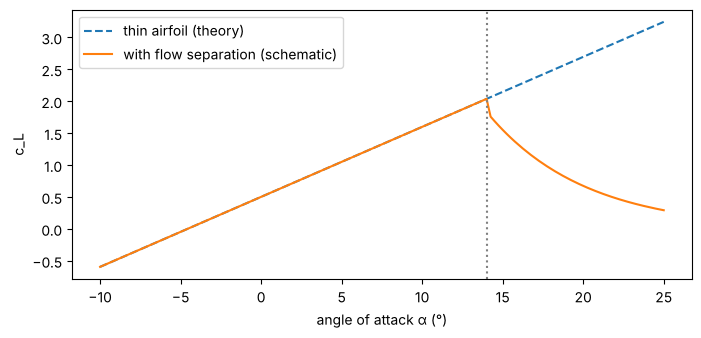

α =  0°: c_L = 0.50, lift  33.9 N (carries 3.46 kg)
α =  5°: c_L = 1.05, lift  70.9 N (carries 7.23 kg)
α = 10°: c_L = 1.60, lift 108.0 N (carries 11.00 kg)


In [3]:
camber = z_viz("camber", 0.04)   # ◀ parameter: airfoil camber (fraction of chord; 0 = symmetric, 0.04 = 4 %)
alpha_stall = 14       # ◀ parameter: stall angle (°), roughly 12–16° from measurements of real airfoils
v, rho, S = 15, 1.2, 0.5     # speed (m/s), density (kg/m³), wing area (m²): a small fixed-wing drone
alpha = np.linspace(-10, 25, 141)
a0 = -2 * camber
cl_theory = 2 * np.pi * (np.radians(alpha) - a0)
cl_real = np.where(alpha <= alpha_stall, cl_theory, 2 * np.pi * (np.radians(alpha_stall) - a0) * np.exp(-(alpha - alpha_stall) / 6) * 0.9)
plt.figure(figsize=(8, 3.5))
plt.plot(alpha, cl_theory, "--", label="thin airfoil (theory)"); plt.plot(alpha, cl_real, label="with flow separation (schematic)")
plt.axvline(alpha_stall, color="gray", ls=":"); plt.xlabel("angle of attack α (°)"); plt.ylabel("c_L"); plt.legend(); plt.show()
for a in (0, 5, 10):
    cl = 2 * np.pi * (np.radians(a) - a0)
    print(f"α = {a:2d}°: c_L = {cl:.2f}, lift {0.5 * rho * v**2 * S * cl:5.1f} N (carries {0.5 * rho * v**2 * S * cl / g:.2f} kg)")

> **✏️ Task 1.** Why does a cambered airfoil lift even at 0° angle of attack and a symmetric one does not? Set `camber = 0`. At what angle would the wing carry 2.5 kg? Why does thin airfoil theory fail beyond the stall angle and what happens to the flow on the upper surface? (The curve beyond stall is only schematic.)

*Your answer:* 

## 3. Two views of one force

A hovering rotor throws air downwards. Momentum theory: thrust T = ṁ · w, where w = 2 v_i is the air speed far below the rotor and ṁ = ρ A v_i the mass flow through the disc. Hence v_i = √(T / (2 ρ A)). The same thrust is also the pressure difference across the disc: Δp = T / A.

> **💻 What the code does:** Defines the function `hover`, which uses momentum theory to compute, for hover, the thrust of one rotor, the disc area, the induced velocity, the mass flow, the disc loading and the ideal power. It shows a table for both drones.

In [4]:
def hover(d, rho):
    T = d["m"] * g / d["n"]                 # thrust of one rotor (N)
    A = np.pi * d["D"] ** 2 / 4             # disc area (m²)
    vi = np.sqrt(T / (2 * rho * A))         # induced velocity (m/s)
    return dict(T=T, A=A, vi=vi, mdot=rho * A * vi, dp=T / A, P_ideal=d["n"] * T * vi)

rows = []
for name, d in DRONES.items():
    h = hover(d, 1.225)
    rows.append({"drone": name, "rotor thrust (N)": h["T"], "disc loading Δp (Pa)": h["dp"], "v_i (m/s)": h["vi"],
                 "ṁ (kg/s)": h["mdot"], "ṁ·2v_i (N)": h["mdot"] * 2 * h["vi"], "ideal power (W)": h["P_ideal"]})
pd.DataFrame(rows).set_index("drone").round(2)

,rotor thrust (N),disc loading Δp (Pa),v_i (m/s),ṁ (kg/s),ṁ·2v_i (N),ideal power (W)
drone,,,,,,
Mavic 3E,2.24,50.12,4.52,0.25,2.24,40.6
Matrice 350,15.87,71.01,5.38,1.47,15.87,341.7


> **✏️ Task 2.** Check that the ṁ · 2 v_i column gives the same number as the rotor thrust. Why are the pressure difference and the momentum of the air thrown down two descriptions of one force, not two forces that add up? Why does the Matrice 350 have a higher disc loading and induced velocity even though its propellers are much larger?

*Your answer:* 

## 4. Real air density: lowland, mountains, warm and cold

Ideal hover power is P = T^(3/2) / √(2 ρ A), so it grows with 1/√ρ. We compute density from pressure, temperature and humidity over the last 92 days. The printed elevation is that of the Open-Meteo model point; for the peaks it is lower than the real summit (Großglockner is 3798 m a.s.l.).

> **💻 What the code does:** Downloads 92 days of pressure, temperature and humidity from Open-Meteo for three sites at different elevations and computes the air density (via the virtual temperature). It prints the model grid-point elevation and the range and median of the density and plots its course.

Open-Meteo: Daily API request limit exceeded. Please try again tomorrow. – retrying


České Budějovice   394 m a.s.l.: ρ 1.078–1.243 kg/m³, median 1.166


Plechý          1356 m a.s.l.: ρ 1.002–1.114 kg/m³, median 1.062


Großglockner    3650 m a.s.l.: ρ 0.810–0.875 kg/m³, median 0.844


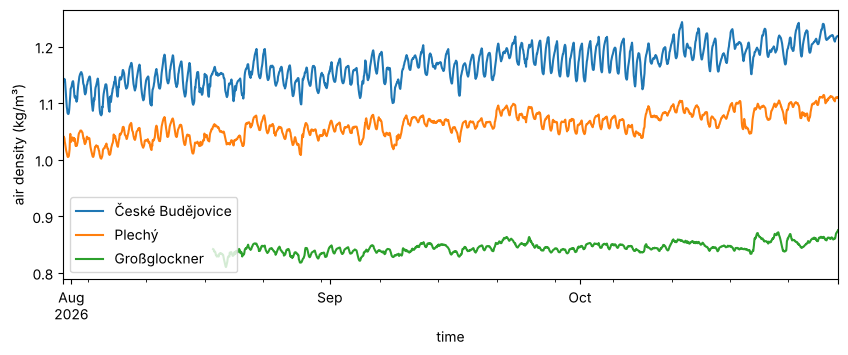

In [5]:
SITES = {"České Budějovice": (48.975, 14.474), "Plechý": (48.772, 13.858), "Großglockner": (47.0745, 12.6941)}
dens = {}
for name, (lat, lon) in SITES.items():
    w = open_meteo({"latitude": lat, "longitude": lon, "past_days": 92, "forecast_days": 1,
                    "hourly": "temperature_2m,relative_humidity_2m,surface_pressure", "timezone": "UTC"})
    df = pd.DataFrame(w["hourly"]).set_index("time")
    T = df.temperature_2m + 273.15
    e = df.relative_humidity_2m / 100 * 6.112 * np.exp(17.62 * df.temperature_2m / (243.12 + df.temperature_2m))
    Tv = T / (1 - 0.378 * e / df.surface_pressure)                    # virtual temperature
    dens[name] = df.surface_pressure * 100 / (287.05 * Tv)
    print(f"{name:14s} {w['elevation']:5.0f} m a.s.l.: ρ {dens[name].min():.3f}–{dens[name].max():.3f} kg/m³, median {dens[name].median():.3f}")
dens = pd.DataFrame(dens); dens.index = pd.to_datetime(dens.index)
ax = dens.plot(figsize=(10, 3.5)); ax.set(ylabel="air density (kg/m³)"); plt.show()

> **💻 What the code does:** For the Mavic 3E it computes the real hover power from the ideal power and the efficiencies `FM`, `eta` for the densest and thinnest air at each site and, from the battery energy, the hover time. It prints it next to the manufacturer's figure.

In [6]:
FM, eta = 0.60, 0.80     # ◀ parameter: rotor efficiency (figure of merit) and motor + ESC efficiency
d = DRONES["Mavic 3E"]
for name in dens:
    for label, rho_ in [("densest", dens[name].max()), ("thinnest", dens[name].min())]:
        P = hover(d, rho_)["P_ideal"] / (FM * eta)
        print(f"{name:14s} {label:9s} ρ = {rho_:.3f}: power {P:5.1f} W, hover {d['E'] / P * 60:4.1f} min")
print(f"the manufacturer states a max. hover time of {d['hover_min']} min")

České Budějovice densest   ρ = 1.243: power  84.0 W, hover 55.0 min
České Budějovice thinnest  ρ = 1.078: power  90.2 W, hover 51.2 min
Plechý         densest   ρ = 1.114: power  88.7 W, hover 52.1 min
Plechý         thinnest  ρ = 1.002: power  93.5 W, hover 49.4 min
Großglockner   densest   ρ = 0.875: power 100.1 W, hover 46.2 min
Großglockner   thinnest  ρ = 0.810: power 104.0 W, hover 44.4 min
the manufacturer states a max. hover time of 38 min


> **✏️ Task 3.** By what percentage is the air on Großglockner thinner than in České Budějovice, and how many per cent more power does the drone need to hover? Check that the power ratio is √(ρ_České Budějovice / ρ_peak). What FM and η would make the hover-time estimate match the manufacturer's figure? Why do manufacturers state endurance under ideal conditions?

*Your answer:* 

> **💻 What the code does:** Computes the hover power of a Mavic 3E with the same mass and propellers from 15 to 60 cm and plots it. The dotted line marks the real propeller.

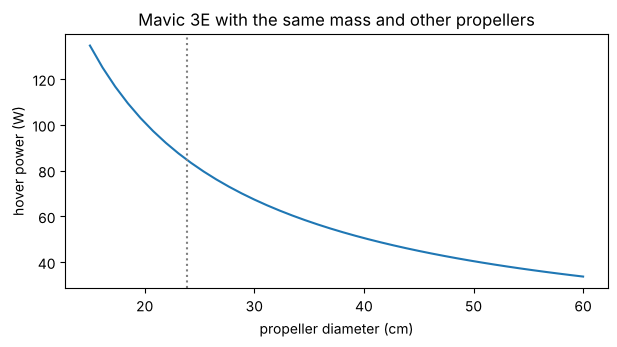

In [7]:
D_list = np.linspace(0.15, 0.6, 40)
P_D = [hover(dict(DRONES["Mavic 3E"], D=D_), 1.225)["P_ideal"] / (FM * eta) for D_ in D_list]
plt.figure(figsize=(7, 3.3)); plt.plot(D_list * 100, P_D); plt.axvline(DRONES["Mavic 3E"]["D"] * 100, color="gray", ls=":")
plt.xlabel("propeller diameter (cm)"); plt.ylabel("hover power (W)"); plt.title("Mavic 3E with the same mass and other propellers"); plt.show()

> **✏️ Task 4.** Why do large slow propellers need less power to hover than small fast ones? Explain it from P = T · v_i: which of the two quantities does a larger disc change? Why then does a small drone not have huge propellers?

*Your answer:* 

## 5. Descent and the vortex ring state

When a drone descends vertically at a speed comparable to the hover induced velocity v_h, the air the rotor pushes down recirculates back through the disc from above. According to Leishman (2006) the vortex ring region lies roughly between 0.5 v_h and 1.5 v_h (the exact boundary depends on the measurements).

> **💻 What the code does:** For both drones it computes the induced hover velocity at the median density at `site`, from it the vortex ring region 0.5–1.5 v_h, and compares it with the manufacturer's maximum descent rate.

In [8]:
v_desc = {"Mavic 3E": 6, "Matrice 350": 7}          # max. descent speed from the data sheets (m/s)
site = "Plechý"                                       # ◀ parameter: site (density = 92-day median)
for name, d in DRONES.items():
    vh = hover(d, dens[site].median())["vi"]
    print(f"{name:12s}: v_h = {vh:.1f} m/s → vortex ring roughly {0.5 * vh:.1f}–{1.5 * vh:.1f} m/s, "
          f"manufacturer's max. descent {v_desc[name]} m/s ({v_desc[name] / vh:.1f} v_h)")

Mavic 3E    : v_h = 4.9 m/s → vortex ring roughly 2.4–7.3 m/s, manufacturer's max. descent 6 m/s (1.2 v_h)
Matrice 350 : v_h = 5.8 m/s → vortex ring roughly 2.9–8.7 m/s, manufacturer's max. descent 7 m/s (1.2 v_h)


> **✏️ Task 5.** At what vertical descent speed does the vortex ring state threaten the Mavic and the Matrice? Does the manufacturer's maximum descent speed lie in this region? Why is it safer to descend at an angle or with forward speed, and why is a fast vertical descent close to the ground dangerous when there is no room to recover?

*Your answer:* 

> **✏️ Extension (optional).** Classmates may have the notebook for other places (Prague, Sněžka and Lomnický štít; Brno, Praděd and Gerlachovský štít; České Budějovice, Plechý and Großglockner). Compare the thinnest air and the Mavic's hover time at the highest site. Why does the model point elevation differ from the real summit elevation, and how does that affect the result?

*Your answer:* 

---
### Data sources and references

- Weather: Open-Meteo.com (CC BY 4.0), https://open-meteo.com
- DJI Mavic 3 Enterprise (3E): take-off weight 915 g, 9453F propellers (9.4″), 77 Wh battery, max. hover time 38 min, max. descent speed 6 m/s; DJI Matrice 350 RTK: weight with TB65 batteries 6.47 kg, max. take-off 9.2 kg, 21″ propellers, 2 × 263 Wh, max. descent speed 7 m/s (DJI data sheets).
- Leishman, J. G. (2006). *Principles of Helicopter Aerodynamics*, 2nd ed. Cambridge University Press (momentum theory, figure of merit, vortex ring state).
- Anderson, J. D. (2017). *Fundamentals of Aerodynamics*, 6th ed. McGraw-Hill (thin airfoil theory).
- Density of moist air via virtual temperature; saturation vapour pressure by the Magnus formula (WMO-No. 8, 2018).

### How to cite

OpenSkyLab (2026). Why a drone flies: lift, momentum and real air density [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/why_drones_fly_hluboka_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*